In [1]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd

df = pd.read_csv("retail_sales_dataset.csv")

df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'retail_sales_dataset.csv'

In [2]:
import os

print("Current folder:", os.getcwd())
print("Files available:", os.listdir())

Current folder: C:\Users\LENOVO
Files available: ['.cache', '.ipynb_checkpoints', '.ipython', '.jupyter', '.matplotlib', '.python_history', '.vscode', '3D Objects', 'AppData', 'Application Data', 'archive.csv', 'archive.zip', 'Contacts', 'Cookies', 'data pipeline.py', 'Documents', 'Downloads', 'Favorites', 'file.csv.ipynb', 'IntelGraphicsProfiles', 'Links', 'Local Settings', 'Microsoft', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TM.blf', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'output.csv', 'people.csv', 'Pictures', 'pipe.y', 'pipeline.log', 'pipeline.py', 'PrintHood', 'program.py', 'purna', 'Recent', 'Retail-Sales-EDA.ipynb', 'retail_sales_data_cleaning_practice.csv', 'salesforecast.png', 'sales_data.csv', 'Saved Ga

In [3]:
import os

for file in os.listdir():
    if file.endswith(".csv"):
        print(file)

archive.csv
output.csv
people.csv
retail_sales_data_cleaning_practice.csv
sales_data.csv


In [4]:
import pandas as pd

df = pd.read_csv("retail_sales_data_cleaning_practice.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (30, 6)


,Order ID,Date,Region,Category,Sales,Status
0,ORD001,01-10-2026,South,Electronics,15000,Completed
1,ORD002,05/10/2026,North,furniture,8000,Pending
2,ORD003,01-10-2026,South,Electronics,15000,Completed
3,ORD004,NaN,East,Furniture,12000,Completed
4,ORD005,15-10-2026,South,Electronics,-500,Pending


In [5]:
# 1. Dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types and Non-Null Counts:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (30, 6)

Column Names:
['Order ID', 'Date', 'Region', 'Category', 'Sales', 'Status']

Data Types and Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Order ID  30 non-null     str  
 1   Date      29 non-null     str  
 2   Region    30 non-null     str  
 3   Category  29 non-null     str  
 4   Sales     30 non-null     int64
 5   Status    30 non-null     str  
dtypes: int64(1), str(5)
memory usage: 1.5 KB

Missing Values:
Order ID    0
Date        1
Region      0
Category    1
Sales       0
Status      0
dtype: int64

Duplicate Rows:
0


In [6]:

# 2. Descriptive statistics
display(df.describe(include="all"))

print("Mean Sales:", df["Sales"].mean())
print("Median Sales:", df["Sales"].median())
print("Mode Sales:", df["Sales"].mode().tolist())
print("Standard Deviation:", df["Sales"].std())


,Order ID,Date,Region,Category,Sales,Status
count,30,29,30,29,30.000000,30
unique,30,28,5,7,NaN,3
top,ORD001,01-10-2026,South,Clothing,NaN,Completed
freq,1,2,8,8,NaN,22
mean,NaN,NaN,NaN,NaN,9653.333333,NaN
std,NaN,NaN,NaN,NaN,5645.366323,NaN
min,NaN,NaN,NaN,NaN,-500.000000,NaN
25%,NaN,NaN,NaN,NaN,5425.000000,NaN
50%,NaN,NaN,NaN,NaN,7800.000000,NaN
75%,NaN,NaN,NaN,NaN,13200.000000,NaN


Mean Sales: 9653.333333333334
Median Sales: 7800.0
Mode Sales: [15000]
Standard Deviation: 5645.3663228828855


In [8]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


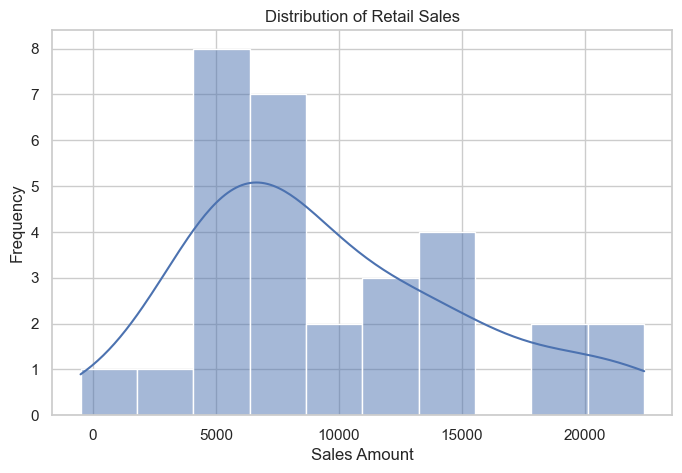

In [9]:

plt.figure(figsize=(8, 5))

sns.histplot(df["Sales"].dropna(), bins=10, kde=True)

plt.title("Distribution of Retail Sales")
plt.xlabel("Sales Amount")
plt.ylabel("Frequency")
plt.show()


Region
West      75900
South     72200
North     70000
East      64300
south      7200
Name: Sales, dtype: int64


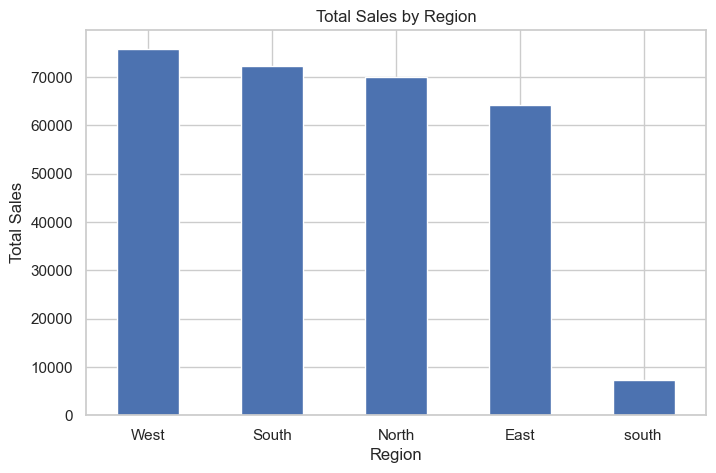

In [10]:

region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

print(region_sales)

region_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.show()


Category
Electronics      93300
Furniture        73000
Clothing         55900
Grocery          32300
electronics      18200
furniture         8000
 Electronics      -500
Name: Sales, dtype: int64


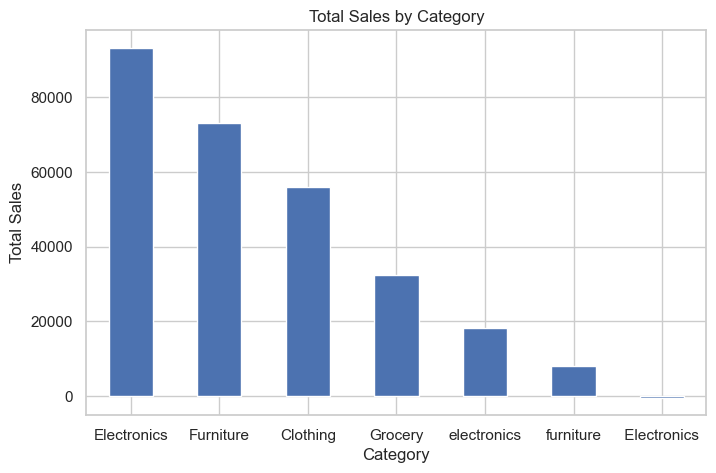

In [11]:

category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

print(category_sales)

category_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.show()


In [12]:
# Remove extra spaces and standardize category names
df["Category"] = df["Category"].str.strip().str.title()

# Check the updated categories
print(df["Category"].unique())

<StringArray>
['Electronics', 'Furniture', 'Clothing', nan, 'Grocery']
Length: 5, dtype: str


In [13]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Display negative sales records
print("Negative sales records:")
display(df[df["Sales"] < 0])

Missing values:
Order ID    0
Date        1
Region      0
Category    1
Sales       0
Status      0
dtype: int64
Duplicate rows: 0
Negative sales records:


,Order ID,Date,Region,Category,Sales,Status
4,ORD005,15-10-2026,South,Electronics,-500,Pending


In [14]:
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print(df["Date"].dtype)
print("Missing dates:", df["Date"].isnull().sum())

datetime64[us]
Missing dates: 17


Category
Electronics    111000
Furniture       81000
Clothing        55900
Grocery         32300
Name: Sales, dtype: int64


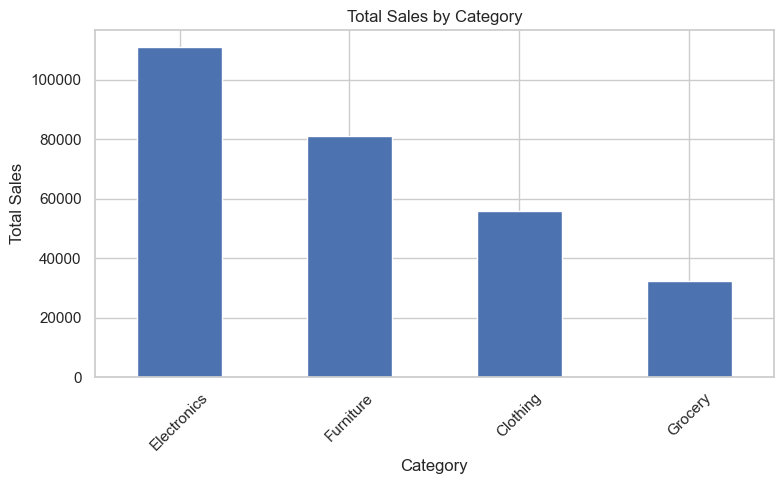

In [15]:
import matplotlib.pyplot as plt

category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)

category_sales.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
print("Sales Statistics")
print("Mean:", df["Sales"].mean())
print("Median:", df["Sales"].median())
print("Mode:", df["Sales"].mode().tolist())
print("Standard Deviation:", df["Sales"].std())

display(df.describe(include="all"))

Sales Statistics
Mean: 9653.333333333334
Median: 7800.0
Mode: [15000]
Standard Deviation: 5645.3663228828855


,Order ID,Date,Region,Category,Sales,Status
count,30,13,30,29,30.000000,30
unique,30,NaN,5,4,NaN,3
top,ORD001,NaN,South,Clothing,NaN,Completed
freq,1,NaN,8,8,NaN,22
mean,NaN,2026-11-17 14:46:09.230769,NaN,NaN,9653.333333,NaN
min,NaN,2026-10-01 00:00:00,NaN,NaN,-500.000000,NaN
25%,NaN,2026-10-25 00:00:00,NaN,NaN,5425.000000,NaN
50%,NaN,2026-11-14 00:00:00,NaN,NaN,7800.000000,NaN
75%,NaN,2026-12-16 00:00:00,NaN,NaN,13200.000000,NaN
max,NaN,2027-01-13 00:00:00,NaN,NaN,22400.000000,NaN


Region
West      75900
South     72200
North     70000
East      64300
south      7200
Name: Sales, dtype: int64


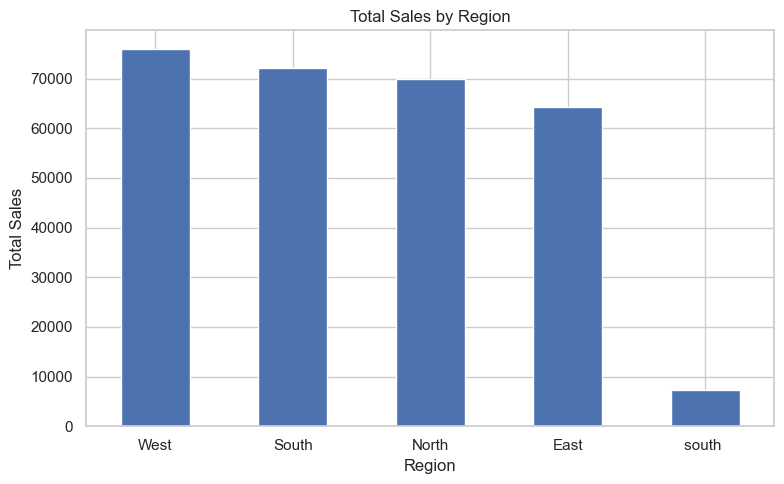

In [17]:
import matplotlib.pyplot as plt

region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

print(region_sales)

region_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Status
Completed    22
Pending       7
Cancelled     1
Name: count, dtype: int64


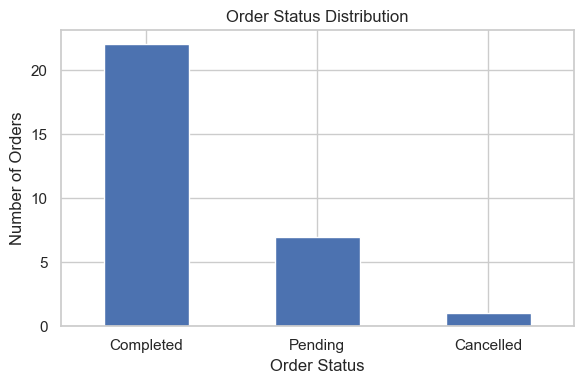

In [18]:
print(df["Status"].value_counts())

df["Status"].value_counts().plot(kind="bar", figsize=(6, 4))
plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Date
2026-10-01    30000
2026-10-15     -500
2026-10-25     9400
2026-10-30    18200
2026-11-02    11000
2026-11-14    12600
2026-11-22    22400
2026-12-04     5200
2026-12-16     7600
2026-12-28     6900
2027-01-01    21000
2027-01-13     7500
Name: Sales, dtype: int64


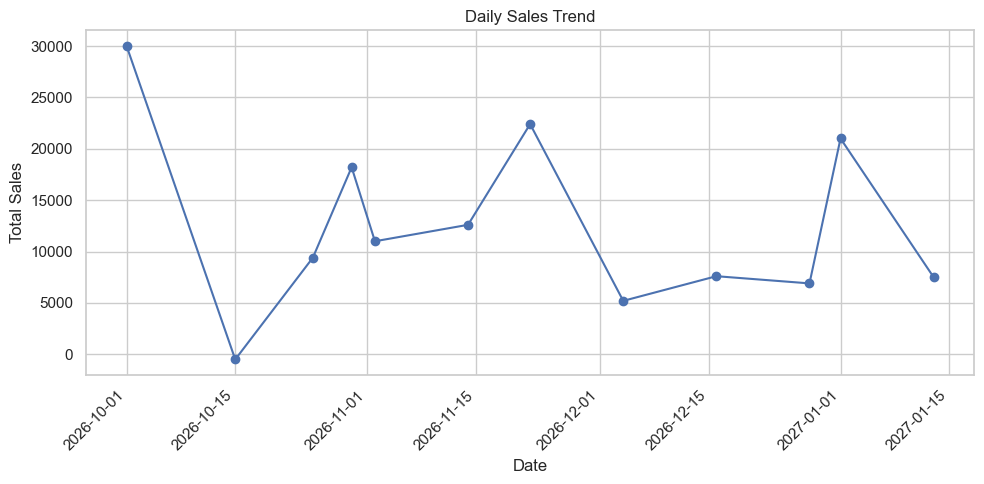

In [19]:
# Group sales by date
daily_sales = df.groupby("Date")["Sales"].sum().sort_index()

print(daily_sales)

# Plot daily sales trends
daily_sales.plot(figsize=(10, 5), marker="o")

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
print("RETAIL SALES ANALYSIS - KEY INSIGHTS")

print("\n1. Sales by Category:")
print(category_sales)

print("\n2. Sales by Region:")
print(region_sales)

print("\n3. Order Status:")
print(df["Status"].value_counts())

print("\n4. Overall Sales:", df["Sales"].sum())
print("5. Average Sales:", round(df["Sales"].mean(), 2))

RETAIL SALES ANALYSIS - KEY INSIGHTS

1. Sales by Category:
Category
Electronics    111000
Furniture       81000
Clothing        55900
Grocery         32300
Name: Sales, dtype: int64

2. Sales by Region:
Region
West      75900
South     72200
North     70000
East      64300
south      7200
Name: Sales, dtype: int64

3. Order Status:
Status
Completed    22
Pending       7
Cancelled     1
Name: count, dtype: int64

4. Overall Sales: 289600
5. Average Sales: 9653.33
